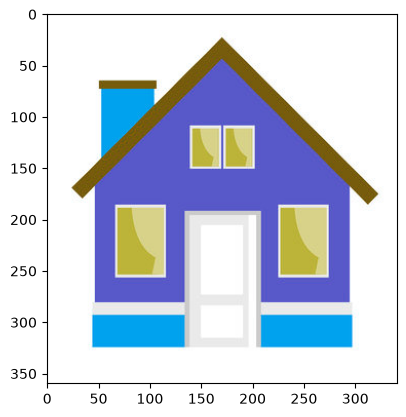

In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
image = cv.imread('test2.jpg')
plt.imshow(image)
plt.show()

In [3]:
LUMA = np.array([0.299, 0.587, 0.114]) # Luminanace
def convert2grey(img):
    return np.round(img[..., :3] @ LUMA).astype(np.uint8)

In [5]:
image.shape

(360, 341, 3)

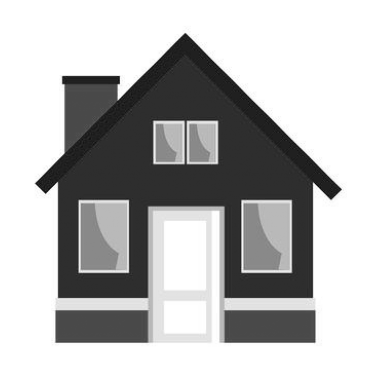

In [8]:
grey = convert2grey(image)
plt.imshow(grey, cmap = 'grey')
plt.axis("off")
plt.show()

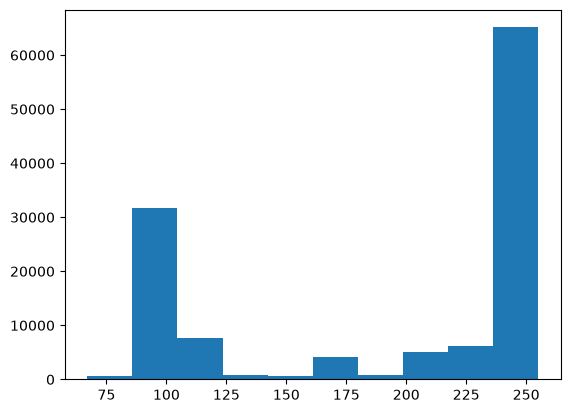

In [11]:
flatted_grey = grey.flatten()
plt.hist(flatted_grey)
plt.show()

In [21]:
CDF_LIST = []
for i in range(0, 256):
    bin_i = len(flatted_grey[flatted_grey <= i])
    CDF_LIST.append(bin_i)
CDF_LIST = np.array(CDF_LIST)
len(CDF_LIST)

256

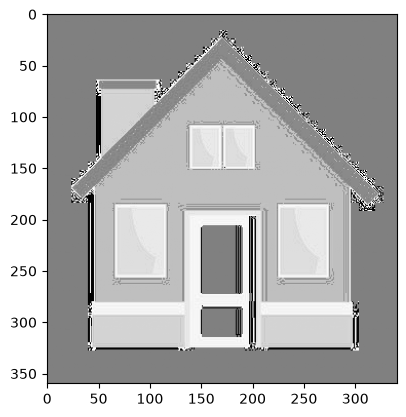

In [ ]:
CDF_min = CDF_LIST[CDF_LIST > 0].min()
lut = np.round(((CDF_LIST - CDF_min) / (grey.shape[0] * grey.shape[1] - CDF_min)) * 255).astype(np.int8)

CDF_grey = lut[grey]
plt.imshow(CDF_grey, cmap="grey")
plt.show()

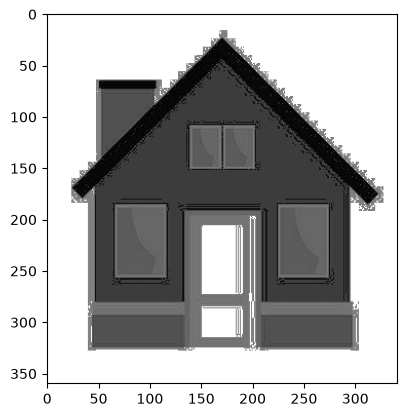

In [33]:
plt.imshow(after_CDF, cmap='grey')

In [36]:
hist = np.bincount(grey.ravel(), minlength=256)
cdf = hist.cumsum()
cdf_min = cdf[cdf > 0].min()
lut = np.round((cdf - cdf_min) / (grey.size - cdf_min) * 255).astype(np.uint8)
equalized = lut[grey]

# So sánh với OpenCV
# import cv2; print(np.abs(equalized.astype(int) - cv2.equalizeHist(grey)).max())

In [32]:
np.asarray(binSum)

array([     0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      2,      5,      6,     10,     11,
           19,     32,     42,     63,     82,    115,    149,    188,
          244,    295,    373,    465,    571,    716,    878,   1144,
         1577,   1961,   2524,   4275,   4856,   5323,   5727,   6073,
         6482,   6998,   7344,   8367,   9366,  29552,  30646,  31670,
        32348,  32500,  32604,  32807,  32938,  33048,  33078,  33093,
      

In [30]:
cdf

array([     0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      0,      0,      0,      0,      0,
            0,      0,      0,      2,      5,      6,     10,     11,
           19,     32,     42,     63,     82,    115,    149,    188,
          244,    295,    373,    465,    571,    716,    878,   1144,
         1577,   1961,   2524,   4275,   4856,   5323,   5727,   6073,
         6482,   6998,   7344,   8367,   9366,  29552,  30646,  31670,
        32348,  32500,  32604,  32807,  32938,  33048,  33078,  33093,
      

In [38]:
lut

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   1,   1,   1,   1,   1,   1,   2,   2,   3,   4,   5,
         9,  10,  11,  12,  13,  13,  15,  15,  17,  19,  61,  64,  66,
        67,  68,  68,  68,  68,  69,  69,  69,  69,  69,  69,  69,  69,
        69,  69,  70,  70,  71,  82,  83,  84,  84,  84,  84,  84,  85,
        85,  85,  85,  85,  85,  85,  85,  85,  85,  85,  85,  85,  85,
        85,  85,  85,  85,  85,  85,  85,  85,  85,  85,  86,  86,  86,
        86,  86,  86,  86,  86,  86,  86,  86,  87,  87,  88,  88,  92,
        93,  94,  94,  94,  94,  94,  94,  95,  95,  95,  95,  9

(array([101.,   0.,  21.,  81.,  50.,   2.,   0.,   0.,   0.,   1.]),
 array([  0. ,  25.5,  51. ,  76.5, 102. , 127.5, 153. , 178.5, 204. ,
        229.5, 255. ]),
 <BarContainer object of 10 artists>)

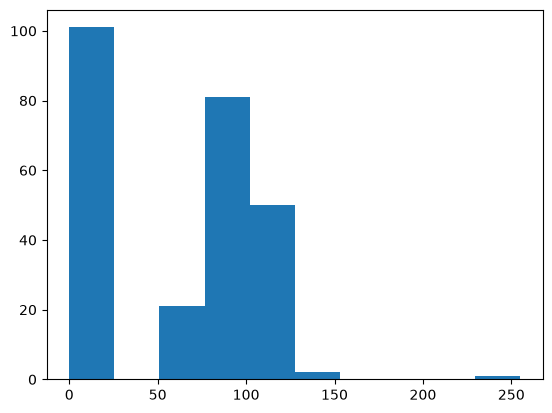

In [29]:
plt.hist(lut)